# Step 4: Who spoke when (NeMo speaker diarization)

Finds **who spoke when** in a recording using one NVIDIA model, Nemotron-3-Diarization (up to 8 speakers). It does not transcribe speech.

The model (about 190 MB) downloads from Hugging Face the first time. If you upgrade NeMo, restart the kernel before running again.

In [1]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
from nemo.collections.asr.models import SortformerEncLabelModel

# Find the project folder (works from any notebook folder)
project_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "pyproject.toml").is_file() and (path / "src").is_dir()
)

# All audio from steps 1 and 2 ends up here
wavs = sorted((project_root / "data" / "raw_audios").glob("*.wav"))
for i, p in enumerate(wavs):
    print(f"{i:2d}  {p.name}")

/Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 0  abuser.wav


## 1. Pick a file and prepare it

Change the number in `wavs[0]` to pick a file from the list above. `TEST_MINUTES` keeps only the first few minutes of a long recording for a quick test.

Results go to `outputs/diarization/<file name>/nemotron/` and are overwritten each time you run the same file.

In [2]:
audio_path = wavs[0]   # change the number to pick another file
TEST_MINUTES = None    # e.g. 5 for a quick test on a long podcast; None = whole file

output_dir = project_root / "outputs" / "diarization" / audio_path.stem / "nemotron"
output_dir.mkdir(parents=True, exist_ok=True)

# The model wants 16 kHz, mono. Make a copy in that format; the original stays untouched.
model_audio = output_dir / "audio_16k_mono.wav"
command = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(audio_path)]
if TEST_MINUTES:
    command += ["-t", str(TEST_MINUTES * 60)]
command += ["-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le", str(model_audio)]
subprocess.run(command, check=True)
print("Model input:", model_audio.relative_to(project_root))

Model input: outputs/diarization/abuser/nemotron/audio_16k_mono.wav


## 2. Load the model

The model reads audio in chunks. The settings are counted in 80 ms frames:

- `chunk_len = 340`: about 27 s of audio per chunk
- `chunk_right_context = 40`: about 3 s of look-ahead past each chunk
- `spkcache_len = 264`: about 21 s of saved speech the model uses to remember each voice, so the same person keeps the same label from chunk to chunk

Longer chunks usually give better results but use more memory. It runs on CPU.

In [3]:
diar_model = SortformerEncLabelModel.from_pretrained("nvidia/Nemotron-3-Diarization")
diar_model.eval()

diar_model.sortformer_modules.chunk_len = 340
diar_model.sortformer_modules.chunk_right_context = 40
diar_model.sortformer_modules.fifo_len = 40
diar_model.sortformer_modules.spkcache_update_period = 300
diar_model.sortformer_modules.spkcache_len = 264
diar_model._check_streaming_parameters()

print("Running on:", next(diar_model.parameters()).device)

[NeMo W 2026-11-18 16:46:12 modelPT:192] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    manifest_filepath: null
    validate_manifest_paths: false
    sample_rate: 16000
    num_spks: 8
    session_len_sec: 105
    soft_targets: false
    batch_size: 42
    shuffle: true
    num_workers: 18
    pin_memory: true
    use_lhotse: false
    subsegment_mode: true
    subsegment_single_chunk_min_len_sec: 45
    subsegment_two_chunks_rate: 0.5
    subsegment_two_chunk_min_len_sec: 22
    subsegment_nspk_bias: 1.5
    subsegment_start_guard_sec: 0.25
    subsegment_min_first_spk_sec: 0.5
    subsegment_splice_silence_sec: 0.1
    
[NeMo W 2026-11-18 16:46:12 modelPT:199] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the

[NeMo I 2026-11-18 16:46:12 save_restore_connector:309] Model SortformerEncLabelModel was successfully restored from /Users/macbook/.cache/huggingface/hub/models--nvidia--Nemotron-3-Diarization/snapshots/52a432672732425e4c19765b9fec9b5810e6f4ba/Nemotron-3-Diarization.nemo.


[NeMo W 2026-11-18 16:46:12 sortformer_modules:241] spkcache_update_period (300) is less than chunk_len (340). The effective update period will be 340.


Running on: cpu


## 3. Run diarization

Labels like `speaker_0` are anonymous and only mean something inside this recording. Turns that overlap in time mean two people talking at once.

In [4]:
segments_text, probabilities = diar_model.diarize(
    audio=[str(model_audio)], batch_size=1, include_tensor_outputs=True
)

# Each line looks like "12.340 15.020 speaker_1". Turn it into numbers and sort by time.
turns = []
for line in segments_text[0]:
    start, end, speaker = line.split()
    turns.append((float(start), float(end), speaker))
turns.sort()

for start, end, speaker in turns[:20]:
    print(f"{speaker}  {start:8.2f}s -> {end:8.2f}s  ({end - start:.1f}s)")
print(f"... {len(turns)} turns in total")

[NeMo I 2026-11-18 16:46:14 vad_utils:90] No postprocessing YAML file has been provided. Default postprocessing configurations will be applied.


[NeMo W 2026-11-18 16:46:14 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: validate_manifest_paths,subsampling_factor,subsegment_single_chunk_min_len_sec,subsegment_nspk_bias,soft_label_thres,subsegment_start_guard_sec,subsegment_two_chunk_min_len_sec,subsegment_splice_silence_sec,session_len_sec,subsegment_min_first_spk_sec,subsegment_mode,subsegment_two_chunks_rate,num_spks
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-18 16:46:14 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
[NeMo W 2026-11-18 16:46:14 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/nn/attention/flex_attention.py:2621: UserWarning: flex_attention called without torch.compile() - this will use an un

speaker_0      0.06s ->     3.00s  (2.9s)
speaker_0      3.05s ->     3.77s  (0.7s)
speaker_1      4.09s ->     5.08s  (1.0s)
speaker_0      5.17s ->     8.98s  (3.8s)
speaker_0      9.23s ->    11.36s  (2.1s)
speaker_0     11.61s ->    16.53s  (4.9s)
speaker_1     16.99s ->    17.04s  (0.1s)
speaker_0     17.20s ->    26.76s  (9.6s)
speaker_0     27.65s ->    34.08s  (6.4s)
speaker_2     30.70s ->    31.78s  (1.1s)
speaker_2     33.60s ->    35.26s  (1.7s)
speaker_0     34.64s ->    43.44s  (8.8s)
speaker_2     43.80s ->    44.41s  (0.6s)
speaker_0     44.94s ->    48.08s  (3.1s)
speaker_0     48.09s ->    48.16s  (0.1s)
speaker_0     48.19s ->    49.40s  (1.2s)
speaker_2     49.06s ->    51.16s  (2.1s)
speaker_0     50.93s ->    58.09s  (7.2s)
speaker_2     53.78s ->    54.40s  (0.6s)
speaker_2     57.81s ->    58.81s  (1.0s)
... 21 turns in total


## 4. Save and inspect the result

Saves an RTTM file (one line per turn: start, duration, speaker), prints each speaker's total talk time and draws a timeline.

A "speaker" with only a few very short turns may not be a real person. Check by listening to those moments.

Saved: outputs/diarization/abuser/nemotron/abuser.rttm
speaker_0:   58.2s
speaker_1:    1.0s
speaker_2:    7.1s


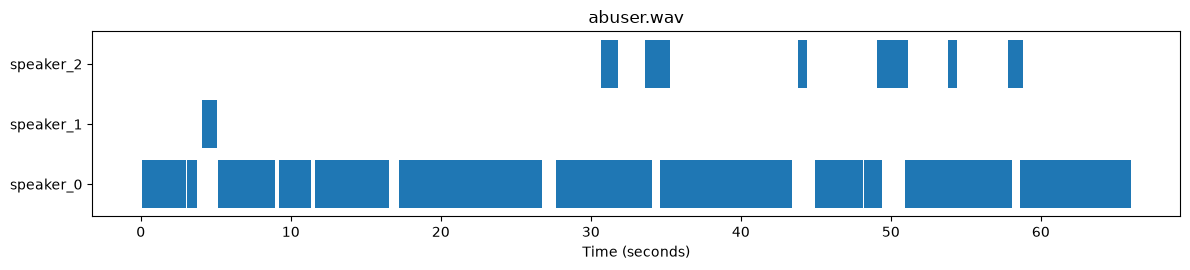

In [5]:
# Save the result as an RTTM file (the standard "who spoke when" format)
rttm_path = output_dir / f"{audio_path.stem}.rttm"
with open(rttm_path, "w") as f:
    for start, end, speaker in turns:
        f.write(f"SPEAKER {audio_path.stem} 1 {start:.3f} {end - start:.3f} <NA> <NA> {speaker} <NA> <NA>\n")
print("Saved:", rttm_path.relative_to(project_root))

# How long each speaker talks in total
speakers = sorted({speaker for _, _, speaker in turns})
for speaker in speakers:
    total = sum(end - start for start, end, s in turns if s == speaker)
    print(f"{speaker}: {total:6.1f}s")

# Timeline: one row per speaker. Bars that overlap in time = people talking at once.
fig, ax = plt.subplots(figsize=(12, 0.6 * len(speakers) + 1))
for row, speaker in enumerate(speakers):
    bars = [(start, end - start) for start, end, s in turns if s == speaker]
    ax.broken_barh(bars, (row - 0.4, 0.8))
ax.set_yticks(range(len(speakers)), speakers)
ax.set_xlabel("Time (seconds)")
ax.set_title(audio_path.name)
plt.tight_layout()
plt.show()